# Проект. Исследование стартапов

- Автор: Айнур Аймурзиева
- Дата: 14.07.2026

## Введение

## Цель и задачи  

**Цель:** Провести исследовательский анализ данных по динамике и структуре финансирования стартапов.

**Задачи:**
1. Загрузка и предобработка данных
2. Инжиниринг признаков
3. Работа с выбросами и анализ
4. Анализ динамики
5. Итоговый вывод и рекомендации

## Данные

Таблица `cb_investments`
Содержит информацию о компаниях и состоявшемся финансировании:

- `name` — название компании;
- `homepage_url` — ссылка на сайт компании;
- `category_list` — категории, в которых работает компания. Указываются через |;
- `market` — основной рынок или отрасль компании;
- `funding_total_usd` — общий объём привлечённых инвестиций в долларах США;
- `status` — текущий статус компании, например, operating, closed и так далее;
- `country_code` — код страны, например USA;
- `state_code` — код штата или региона, например CA;
- `region` — регион, например SF Bay Area;
- `city` — город, в котором расположена компания;
- `funding_rounds` — общее число раундов финансирования;
- `participants` — число участников в раундах финансирования;
- `founded_at` — дата основания компании;
- `founded_month` — месяц основания в формате YYYY-MM;
- `founded_quarter` — квартал основания в формате YYYY-QN;
- `founded_year` — год основания;
- `first_funding_at` — дата первого финансирования;
- `mid_funding_at` — дата среднего по времени раунда финансирования;
- `last_funding_at` — дата последнего финансирования;
- `seed` — сумма инвестиций на посевной стадии;
- `venture` — сумма венчурных инвестиций;
- `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг;
- `undisclosed` — сумма финансирования нераскрытого типа;
- `convertible_note` — сумма инвестиций через конвертируемые займы;
- `debt_financing` — сумма долгового финансирования;
- `angel` — сумма инвестиций от бизнес-ангелов;
- `grant` — сумма полученных грантов;
- `private_equity` — сумма инвестиций в виде прямых (частных) вложений;
- `post_ipo_equity` — сумма финансирования после IPO;
- `post_ipo_debt` — сумма долгового финансирования после IPO;
- `secondary_market` — сумма сделок на вторичном рынке;
- `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг;
- `round_A — round_H` — сумма инвестиций в соответствующем раунде.

Таблица `cb_returns`
Содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов:
- `year` — год возврата средств;
- `seed` — сумма возвратов от посевных инвестиций;
- `venture` — сумма возвратов от венчурных инвестиций;
- `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу;
- `undisclosed` — сумма возвратов нераскрытого типа;
- `convertible_note` — сумма возвратов через конвертируемые займы;
- `debt_financing` — сумма возвратов от долгового финансирования;
- `angel` — сумма возвратов бизнес-ангелам;
- `grant `— сумма возвратов по грантам;
- `private_equity` — сумма возвратов прямых (частных) вложений;
- `post_ipo_equity` — сумма возвратов от IPO;
- `post_ipo_debt` — сумма возвратов от долгового IPO;
- `secondary_market` — сумма возвратов от сделок на вторичном рынке;
- `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

In [1]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Функция подсчета пропусков
def missing_table(df):
    missing_df = pd.DataFrame({
        'Количество пропусков': df.isnull().sum(),
        'Доля пропусков (%)': (df.isnull().mean() * 100).round(2)
    })

    missing_df = missing_df.sort_values('Количество пропусков', ascending=False)
    return missing_df

Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

In [3]:
# Выгружаем данные в переменные
invest_df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [4]:
return_df = pd.read_csv('https://code.s3.yandex.net/datasets/cb_returns.csv')

Выведите информацию, которая необходима для принятия решений о предобработке.

In [5]:
# Выводим первые строки датафрейма на экран
invest_df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
invest_df.iloc[:, 10:30].head()

,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt
0,1.0,NaN,1636-09-08,NaN,NaN,1636.0,2014-01-06,NaN,2014-01-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90000000.0,0.0,0.0,0.0
1,1.0,NaN,1785-01-01,NaN,NaN,1785.0,2014-05-15,NaN,2014-05-15,0.0,2000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1802-07-19,NaN,NaN,1802.0,2009-07-02,2009-07-02,2009-07-02,0.0,9000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.0,0.0,1817-01-01,NaN,NaN,1817.0,2013-11-21,2013-11-21,2014-11-03,0.0,0.0,0.0,1600000.0,0.0,0.0,0.0,6100000.0,0.0,0.0,0.0
4,1.0,NaN,1826-01-01,NaN,NaN,1826.0,2014-01-14,NaN,2014-01-14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,540000.0,0.0,0.0,0.0


In [7]:
# Выводим информацию о датафрейме
invest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [8]:
# Сохраняем изначальное количество строк до удаления дубликатов
initial_row_count = invest_df.shape[0]
initial_row_count

54294

Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

    
Датасет `cb_investments.csv` содержит 39 столбцов и 54294 строк, в которых представлена информация о компаниях и состоявшемся финансировании.
После первичного анализа данных можно сделать следующие выводы:
- Данные включают как текстовые, так и числовые признаки.
- Большинство столбцов имеют типы `object` и `float64`.
- Значения в столбце `funding_total_usd ` для выполнения дальнейших расчётов необходимо преобразовать в тип float.
- В названиях столбцов ` market` и ` funding_total_usd` присутствуют лишние пробелы, которые следует удалить для удобства дальнейшей работы с данными.
- Столбцы `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at` необходимо преобразовать к типу datetime, чтобы можно было анализировать данные по времени.
- Столбцы `founded_month`, `founded_quarter`, `founded_year` целесообразно привести к числовому типу данных для последующего анализа.
- Пропуски содержатся во всех 39 столбцах.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Теперь познакомимся с данными датасета `cb_returns.csv`.
  

In [9]:
# Выводим первые строки датафрейма на экран
return_df.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [10]:
# Выводим информацию о датафрейме
return_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


    
Датасет `cb_returns.csv` содержит 13 столбцов и 15 строк, в которых представлена информация об объёмах возвратов по годам и типам финансирования в миллионах долларов.
После первичного анализа данных можно сделать следующие выводы:
- Все представленные данные являются числовыми и хранятся в типах данных `int64` или `float64`.
- Пропущенные значения в датасете отсутствуют.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию и названия столбцов написаны в едином виде.
    

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [11]:
# Выводим названия столбцов датафрейма invest_df
invest_df.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [12]:
# Передаём методу rename() словарь с названиями столбцов
invest_df = invest_df.rename(columns={' market ': 'market',
                                  ' funding_total_usd ': 'funding_total_usd'})

In [13]:
# Выводим названия столбцов датафрейма return_df
return_df.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [14]:
# Оптимизируем целочисленный тип данных в датафрейме invest_df
invest_df['funding_total_usd'] = invest_df['funding_total_usd'].str.replace(',','')
invest_df['funding_total_usd'] = pd.to_numeric(invest_df['funding_total_usd'], errors='coerce')

In [15]:
# Проверим типы данных в датафрейме с помощью атрибута dtypes
invest_df.dtypes

name                     object
homepage_url             object
category_list            object
market                   object
funding_total_usd       float64
status                   object
country_code             object
state_code               object
region                   object
city                     object
funding_rounds          float64
participants            float64
founded_at               object
founded_month            object
founded_quarter          object
founded_year            float64
first_funding_at         object
mid_funding_at           object
last_funding_at          object
seed                    float64
venture                 float64
equity_crowdfunding     float64
undisclosed             float64
convertible_note        float64
debt_financing          float64
angel                   float64
grant                   float64
private_equity          float64
post_ipo_equity         float64
post_ipo_debt           float64
secondary_market        float64
product_

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [16]:
# Меняем тип данных на datetime64 в нескольких столбцах с помощью цикла
for column in ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']:
    invest_df[column] = pd.to_datetime(invest_df[column], errors='coerce') 

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [17]:
return_df = return_df.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [18]:
# Выводим количество пустых значений в каждой колонке
missing_table(invest_df)

,Количество пропусков,Доля пропусков (%)
state_code,24133,44.45
mid_funding_at,24006,44.21
participants,23821,43.87
founded_quarter,15812,29.12
founded_month,15812,29.12
founded_at,15741,28.99
founded_year,15740,28.99
funding_total_usd,13387,24.66
city,10972,20.21
region,10129,18.66


- Поскольку доля пропусков в некоторых столбцах достаточно велика, удаление всех строк с пропущенными значениями приведёт к существенной потере данных и может исказить результаты анализа. 
- Текстовые признаки (market, category_list, status, country_code, state_code, region, city) нужно заполнить значением 'unknown', так как отсутствие информации в этих полях не означает отсутствия самой компании и позволяет сохранить наблюдения для дальнейшего анализа.
    

In [19]:
# Заполняем пропуски в текстовых столбцах
for column in ['market', 'category_list', 'status', 'country_code', 'state_code', 'region', 'city']:
    invest_df[column] = invest_df[column].fillna('unknown')

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [20]:
# Проверяем полные дубликаты в датафрейме
duplicates=invest_df.duplicated().sum()
# Выводим дубликаты
display(f"Количество дубликатов:{duplicates}")

'Количество дубликатов:4855'

In [21]:
# Удаляем дубликаты
invest_no_duplicates = invest_df.drop_duplicates()

# Удаляем пропуски в столбце funding_total_usd
invest_no_duplicates= invest_no_duplicates.dropna(subset=['funding_total_usd'])


    
В `funding_total_usd` 24.66% пропусков. 
Несмотря на значительную долю пропусков, эти записи были удалены в соответствии с условием задания. Поскольку данный столбец является одним из ключевых для исследования, заполнение пропусков искусственными значениями могло бы исказить результаты анализа и привести к неверной оценке объёмов финансирования.

Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [22]:
# Функция для заполнения пропусков
def middle_funding(row):
    if pd.isna(row['mid_funding_at']):
        return row['first_funding_at'] + (row['last_funding_at'] - row['first_funding_at']) / 2
    else:
         return row['mid_funding_at']

# Заполните пропуски, используя функцию
invest_no_duplicates['mid_funding_at'] = invest_no_duplicates.apply(middle_funding, axis=1)

Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [23]:
# Удаляем оставшиеся пропуски
invest_no_duplicates= invest_no_duplicates.dropna(subset=['mid_funding_at', 'first_funding_at'])

In [24]:
final_row_count = invest_no_duplicates.shape[0]
# Выводим результаты
print(f"Количество строк до удаления дубликатов и пропусков: {initial_row_count}")
print(f"Количество строк после удаления дубликатов и пропусков: {final_row_count}")
print(f"Количество удаленных дубликатов и пропусков: {initial_row_count-final_row_count}")
print(f"Доля удаленных дубликатов и пропусков: {((initial_row_count-final_row_count)/initial_row_count)}")

Количество строк до удаления дубликатов и пропусков: 54294
Количество строк после удаления дубликатов и пропусков: 40905
Количество удаленных дубликатов и пропусков: 13389
Доля удаленных дубликатов и пропусков: 0.24660183445684605


In [25]:
# Выводим количество пустых значений в каждой колонке
missing_table(invest_no_duplicates)

,Количество пропусков,Доля пропусков (%)
participants,13575,33.19
founded_quarter,8772,21.44
founded_month,8772,21.44
founded_at,8707,21.29
founded_year,8706,21.28
homepage_url,2314,5.66
name,1,0.00
round_B,0,0.00
round_A,0,0.00
product_crowdfunding,0,0.00


    
- Пропуски в текстовых столбцах были заполнены значением unknown
- Были удалены полные дубликаты и строки в которых отсутствовали сведения об общем объёме финансирования  `funding_total_usd`.
- Для столбца `mid_funding_at` пропущенные значения были восстановлены как середина интервала между датами `first_funding_at` и `last_funding_at, что позволило сохранить временную информацию о финансировании компаний

В результате предобработки количество наблюдений уменьшилось с 54 294 до 40 905, то есть было удалено 13 389 строк (24,66%). Несмотря на сокращение объёма выборки, в распоряжении осталось более 40 тысяч наблюдений, что является достаточным для проведения статистического анализа и получения надёжных результатов.

Оставшиеся пропуски содержатся только в признаках, не являющихся критически важными для выполнения задач исследования, поэтому они не оказывают существенного влияния на результаты анализа.

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [26]:
# Функция для категоризации по срокам финансирования
def fund_rounds(row):
    if row['funding_rounds'] == 1:
        return "Единичное финансирование"
    elif ((row['last_funding_at'] - row['first_funding_at'])/pd.to_timedelta('1 D')) <= 365:
        return 'Срок финансирования до года'
    elif ((row['last_funding_at'] - row['first_funding_at'])/pd.to_timedelta('1 D')) > 365:
        return "Срок финансирования более года"
    else:
        return "неизвестно"
#Применяем функцию к отфильтрованному датафрейму
invest_no_duplicates['funding_groups'] = invest_no_duplicates.apply(fund_rounds, axis=1)


In [27]:
invest_no_duplicates.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,funding_groups
0,Harvard University,http://harvard.edu,|Education|,Education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
1,University of New Brunswick,http://www.unb.ca,unknown,unknown,2000000.0,operating,unknown,unknown,unknown,unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование
3,University of Michigan,http://www.umich.edu/,|Education|,Education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование


In [28]:
# Проверяем распределение данных по количеству компаний:
invest_no_duplicates['funding_groups'].value_counts(normalize = True)

Единичное финансирование          0.589488
Срок финансирования более года    0.300477
Срок финансирования до года       0.110035
Name: funding_groups, dtype: float64

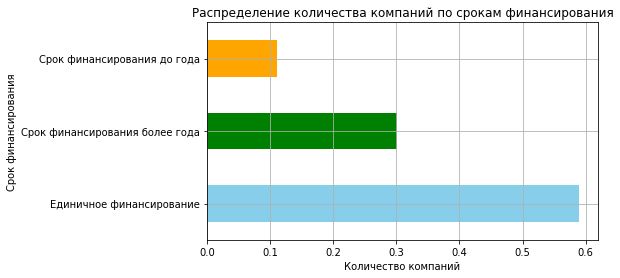

In [29]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 4))

color_map = {
    'Единичное финансирование': 'skyblue',
    'Срок финансирования до года': 'orange',
    'Срок финансирования более года': 'green'
}

colors = [color_map[group] for group in invest_no_duplicates['funding_groups'].value_counts(normalize = True).index]

# Строим столбчатую диаграмму с помощью pandas
invest_no_duplicates['funding_groups'].value_counts(normalize = True).plot(
               kind='barh', # Тип графика - столбчатая диаграмма
               color = colors,
               rot=0, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Распределение количества компаний по срокам финансирования'
)

# Настраиваем оформление графика
plt.ylabel('Срок финансирования')
plt.xlabel('Количество компаний')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

    
- 58.9% компаний получили финансирование только единожды, что делает эту группу наиболее многочисленной. Это свидетельствует о том, что для большинства компаний в датасете было зафиксировано лишь одно событие привлечения инвестиций.
- 30% компаний привлекали финансирование на протяжении более одного года, что указывает на наличие длительного инвестиционного цикла и повторного привлечения капитала.
- Меньшее всего компаний (11%) были профинансированы со сроком до года. Это говорит о том, что относительно небольшая часть компаний завершает процесс привлечения финансирования в короткие сроки.

In [30]:
sum_by_group = invest_no_duplicates.groupby('funding_groups')['funding_total_usd'].sum().astype(int)
share=sum_by_group/sum_by_group.sum()
share.sort_values()

funding_groups
Срок финансирования до года       0.075105
Единичное финансирование          0.306199
Срок финансирования более года    0.618696
Name: funding_total_usd, dtype: float64

In [31]:
color_map = {
    'Единичное финансирование': 'skyblue',
    'Срок финансирования до года': 'orange',
    'Срок финансирования более года': 'green'
}

colors = [color_map[group] for group in share.sort_values().index]

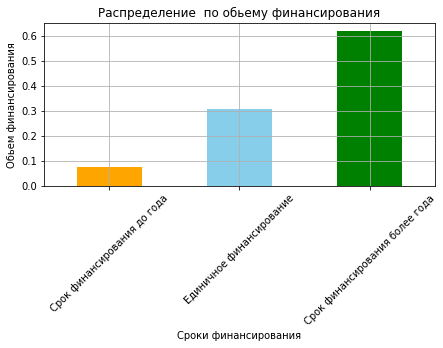

In [32]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
share.sort_values().plot(kind='bar',
               title=f'Распределение  по обьему финансирования',
               color = colors,
               ylabel='Обьем финансирования',
               xlabel='Сроки финансирования',
               rot=45,
               figsize=(7, 3))
plt.grid()

# Выводим график
plt.show()

    
- 61% от общего объёма привлечённых средств получила группа компаний со сроком финансирования более года. Это может свидетельствовать о том, что компании, проходившие несколько инвестиционных раундов в течение длительного периода, в совокупности привлекали значительно больший объём капитала
- 30% средств были выделены компаниям с единичным финансированием. Несмотря на отсутствие повторных раундов финансирования, их доля оказалась достаточно высокой, что указывает на возможность привлечения крупных инвестиций в рамках одного раунда.
- Меньшее всего финансирования (7.5%) были привлечены компаниями со сроком до года. При этом их доля по объёму инвестиций оказалась ниже, чем у компаний с единичным финансированием. Вероятно, что отдельные компании с единичным финансированием привлекали более крупные суммы за один инвестиционный раунд, тогда как компании со сроком финансирования до одного года чаще получали несколько сравнительно небольших вложений.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [33]:
# убираем дубликаты в названиях сегментов
invest_no_duplicates['market'] = invest_no_duplicates['market'].str.lower().str.strip()

In [34]:
# Рассчитываем как часто в датасете встречается каждый из сегментов
segment_m = invest_no_duplicates['market'].value_counts()
segment_m

software                          4812
biotechnology                     3590
unknown                           2503
mobile                            2344
e-commerce                        1866
                                  ... 
supply chain management              1
embedded hardware and software       1
tablets                              1
navigation                           1
point of sale                        1
Name: market, Length: 395, dtype: int64

In [35]:
# Функция для категоризации сегментам
def segment_category(row):
    count = segment_m[row]
    if count > 120:
        return "массовый"
    elif count >= 35:
        return "средний"
    elif count > 0:
        return "нишевый"
    else:
        return "неизвестно"
#Применяем функцию к отфильтрованному датафрейму
invest_no_duplicates['market_category'] = invest_no_duplicates['market'].apply(segment_category)

In [36]:
invest_no_duplicates.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,funding_groups,market_category
0,Harvard University,http://harvard.edu,|Education|,education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
1,University of New Brunswick,http://www.unb.ca,unknown,unknown,2000000.0,operating,unknown,unknown,unknown,unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,business services,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый


In [37]:
# Рассчитываем сколько компаний попадает в каждую из категорий
invest_no_duplicates['market_category'].value_counts(normalize = True)


массовый    0.885857
средний     0.093852
нишевый     0.020291
Name: market_category, dtype: float64

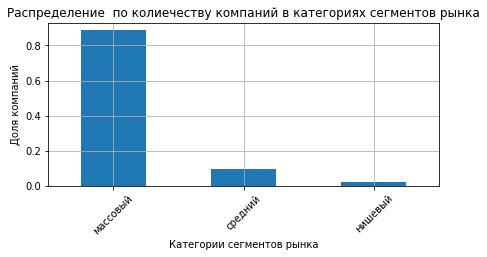

In [38]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
invest_no_duplicates['market_category'].value_counts(normalize = True).plot(kind='bar',
               title=f'Распределение  по колиечеству компаний в категориях сегментов рынка',
               ylabel='Доля компаний',
               xlabel='Категории сегментов рынка',
               rot=45,
               figsize=(7, 3))
plt.grid()

# Выводим график
plt.show()

In [39]:
# Рассчитываем сколько сегментов попадает в каждую из категорий
segment_by_category= invest_no_duplicates.groupby('market_category')['market'].nunique()/invest_no_duplicates['market'].nunique()
segment_by_category.sort_values()

market_category
массовый    0.124051
средний     0.144304
нишевый     0.731646
Name: market, dtype: float64

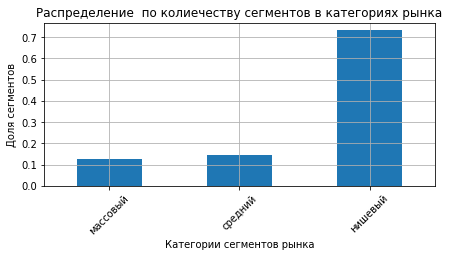

In [40]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
segment_by_category.sort_values().plot(kind='bar',
               title=f'Распределение  по колиечеству сегментов в категориях рынка',
               ylabel='Доля сегментов',
               xlabel='Категории сегментов рынка',
               rot=45,
               figsize=(7, 3))
plt.grid()

# Выводим график
plt.show()

    
 - По количеству компаний наибольшая доля приходится на массовые сегменты рынка, тогда как нишевые сегменты объединяют наименьшее число компаний. Это свидетельствует о том, что большинство компаний сосредоточено в наиболее распространённых направлений деятельности.

 - Однако при рассмотрении количества самих сегментов наблюдается противоположная картина. Наибольшее число сегментов относится к нишевой категории, тогда как массовых сегментов значительно меньше. Это означает, что рынок характеризуется большим разнообразием специализированных направлений, каждое из которых представлено небольшим количеством компаний.
 - Средние сегменты занимают промежуточное положение: как по количеству компаний, так и по числу сегментов их показатели находятся между массовыми и нишевыми категориями.
   

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.

In [41]:
# заменяем значения на заглушки
def mass_segment(row):
    if row['market_category'] == 'нишевый':
        return  'niche'
    elif row['market_category'] == 'средний':
        return 'mid'
    else:
        return row['market']

In [42]:
invest_no_duplicates['market'] = invest_no_duplicates.apply(mass_segment, axis=1)

In [43]:
invest_no_duplicates.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H,funding_groups,market_category
0,Harvard University,http://harvard.edu,|Education|,education,90000000.0,operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
1,University of New Brunswick,http://www.unb.ca,unknown,unknown,2000000.0,operating,unknown,unknown,unknown,unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,mid,9000000.0,operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,средний
3,University of Michigan,http://www.umich.edu/,|Education|,education,7700000.0,operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,массовый
4,Case Western Reserve University,http://www.case.edu,|Education|,education,540000.0,operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,массовый


In [96]:
group_seg = invest_no_duplicates.groupby('market')['name'].count().sort_values()
group_seg

market
startups                 132
public relations         134
nonprofits               135
design                   135
networking               143
entertainment            150
big data                 150
medical                  151
cloud computing          152
automotive               155
social network media     158
video                    188
marketplaces             196
photography              204
sports                   204
apps                     223
technology               238
internet                 241
music                    264
saas                     272
real estate              279
search                   291
messaging                295
news                     301
fashion                  303
travel                   330
hospitality              336
consulting               349
web hosting              424
semiconductors           484
security                 567
manufacturing            596
analytics                667
finance                  828
niche  

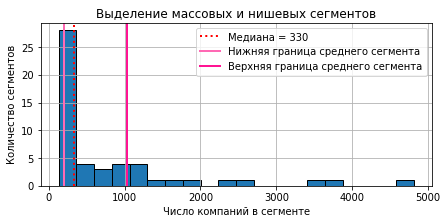

In [97]:
median = group_seg.median()
q1 = group_seg.quantile(0.25)
q3 = group_seg.quantile(0.75)

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
plt.hist(group_seg,
         bins=20,
         edgecolor='black')

plt.axvline(median,
            color='red',
            linestyle=':',
            linewidth=2,
            label=f'Медиана = {median:.0f}')

plt.axvline(q1,
            color='hotpink',
            linewidth=2,
            label='Нижняя граница среднего сегмента')

plt.axvline(q3,
            color='deeppink',
            linewidth=2,
            label='Верхняя граница среднего сегмента')

# Настраиваем оформление графика
plt.title('Выделение массовых и нишевых сегментов')
plt.xlabel('Число компаний в сегменте')
plt.ylabel('Количество сегментов')
# Добавляем сетку графика
plt.grid()
plt.legend()

# Выводим график
plt.show()

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

In [50]:
# Изучаем статистические показатели столбца funding_total_usd
invest_no_duplicates.groupby('market')['funding_total_usd'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
market,,,,,,,,
advertising,1107.0,13068657.0,43448970.0,1000.0,500000.0,2662400.0,11144998.0,1.137000e+09
analytics,667.0,14000210.0,62150291.0,10000.0,500000.0,2899980.0,11079181.0,1.201000e+09
apps,223.0,2781719.0,6160345.0,7500.0,100000.0,632000.0,2169575.0,5.000000e+07
automotive,155.0,24180549.0,133898062.0,500.0,265032.0,2000000.0,10000000.0,1.451000e+09
big data,150.0,10905782.0,27377876.0,11700.0,300000.0,2000000.0,7000000.0,2.000000e+08
biotechnology,3590.0,21120538.0,56531509.0,1000.0,1500000.0,5507500.0,22031670.0,2.400000e+09
clean technology,1180.0,38486552.0,103247186.0,3000.0,1500000.0,7472490.0,28196620.0,1.200000e+09
cloud computing,152.0,11600713.0,25336810.0,10000.0,585305.0,1811000.0,10000000.0,2.311000e+08
consulting,349.0,8695353.0,26315903.0,100.0,125000.0,1150000.0,5330000.0,3.983500e+08


In [51]:
# Изучаем статистические показатели столбца funding_total_usd
invest_no_duplicates.groupby('market_category')['funding_total_usd'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
market_category,,,,,,,,
массовый,36236.0,15855686.0,175929218.0,1.0,375000.0,2000000.0,10000000.0,3.007950e+10
нишевый,830.0,17674317.0,85200426.0,100.0,150000.0,972500.0,5387728.0,1.498515e+09
средний,3839.0,16067484.0,97314348.0,100.0,250000.0,1491477.0,7785050.0,3.500000e+09


<Figure size 1440x720 with 0 Axes>

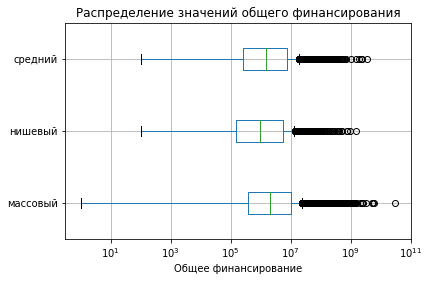

In [52]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(20, 10))

# Строим диаграмму размаха значений 
invest_no_duplicates.boxplot(column='funding_total_usd', by='market_category', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений общего финансирования')
plt.xlabel('Общее финансирование')
plt.xscale('log')
plt.suptitle('')

# Выводим график
plt.show()

    
 - Во всех трёх категориях рынка присутствуют выбросы.
 - Наиболее широкий разброс значений наблюдается в массовых сегментах, что объясняется большим количеством компаний и наличием крупных инвестиционных сделок. В средних и нишевых сегментах разброс финансирования меньше, однако аномально большие значения также присутствуют.
 - В качестве типичного объёма финансирования можно рассматривать значения, лежащие в пределах межквартильного интервала:

    - массовые сегменты — от 375 тыс. до 10 млн долларов
    - средние сегменты — от 250 тыс. до 7,8 млн долларов;
    - нишевые сегменты — от 150 тыс. до 5,4 млн долларов.

Таким образом, по мере перехода от массовых к нишевым сегментам уменьшается типичный объём привлекаемого финансирования, однако во всех категориях встречаются компании с объёмами инвестиций, значительно превышающими основной диапазон значений.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

In [53]:
grouped_df=invest_no_duplicates.groupby('market')['funding_total_usd']

In [54]:
# Вычисляем квартили Q1 и Q3
Q1 = grouped_df.transform(lambda x : x.quantile(0.25))
Q3 = grouped_df.transform(lambda x : x.quantile(0.75))

# Вычисляем межквартильный размах IQR
IQR = Q3 - Q1

# Определяем верхний порог для выбросов
upper_bound= Q3 + 1.5 * IQR
lower_bound=Q1 - 1.5 * IQR

In [55]:
invest_no_duplicates['is_anomaly']=(invest_no_duplicates['funding_total_usd']>upper_bound)|(invest_no_duplicates['funding_total_usd']<lower_bound)

In [56]:
invest_no_duplicates.groupby('market')['is_anomaly'].mean().sort_values(ascending=False).head(20)

market
real estate        0.172043
entertainment      0.166667
consulting         0.166189
search             0.164948
cloud computing    0.164474
saas               0.161765
photography        0.161765
technology         0.159664
video              0.159574
niche              0.159036
travel             0.154545
networking         0.153846
internet           0.153527
big data           0.153333
marketplaces       0.153061
unknown            0.149021
mid                0.144829
e-commerce         0.144159
apps               0.143498
automotive         0.141935
Name: is_anomaly, dtype: float64

Метод IQR показал, что наибольшая доля компаний с аномальным объёмом финансирования наблюдается в сегментах `Real Estate` (17.2%), `Entertainment` (16.7%) и `Consulting` (16.6%). Это означает, что именно в этих сегментах чаще встречаются компании, объём привлечённого финансирования которых существенно отличается от типичных значений для соответствующего сегмента.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [57]:
# Проверяем самую первую дату
invest_no_duplicates['first_funding_at'].min() 

Timestamp('1921-09-01 00:00:00')

In [58]:
# Проверяем последнюю дату
invest_no_duplicates['last_funding_at'].max() 

Timestamp('2014-12-31 00:00:00')

In [59]:
# Проверяем данные за 2014 год в столбце last_funding_at
invest_no_duplicates[invest_no_duplicates['last_funding_at'].dt.year==2014]['last_funding_at'].dt.month.value_counts().sort_index()

1     1178
2      947
3     1072
4     1077
5     1036
6     1229
7     1254
8     1064
9     1134
10    1139
11     732
12      52
Name: last_funding_at, dtype: int64

In [60]:
# Проверяем данные за 2014 год в столбце first_funding_at
invest_no_duplicates[invest_no_duplicates['first_funding_at'].dt.year==2014]['first_funding_at'].dt.month.value_counts().sort_index()

1     810
2     635
3     661
4     593
5     549
6     669
7     671
8     525
9     538
10    492
11    311
12     23
Name: first_funding_at, dtype: int64

In [61]:
# Исключяем из датасета компании, которые получили аномальное финансирование
new_df=invest_no_duplicates[~(invest_no_duplicates['is_anomaly'] == True)]

In [62]:
# Высчитываем количество раундов финансирования в год
rounds_per_year = new_df.groupby(new_df['mid_funding_at'].dt.year)['funding_rounds'].sum()
rounds_per_year

mid_funding_at
1921        1.0
1960        2.0
1979        1.0
1982        3.0
1983        1.0
1984        2.0
1985        3.0
1987        2.0
1989        1.0
1990        1.0
1992        5.0
1993        1.0
1994        4.0
1995        9.0
1996        8.0
1997        5.0
1998       15.0
1999       43.0
2000      113.0
2001       66.0
2002       98.0
2003      125.0
2004      181.0
2005      948.0
2006     1849.0
2007     2842.0
2008     3663.0
2009     4617.0
2010     6136.0
2011     7578.0
2012     9705.0
2013    12880.0
2014     7122.0
Name: funding_rounds, dtype: float64

In [63]:
# Отфильтровываем новый датасет
filtered_df=new_df[new_df['mid_funding_at'].dt.year>=2000]

    
- По анализу столбцов `last_funding_at` и `first_funding_at` было выявлено, что данные охватывают период до 31 декабря 2014 года. Записи присутствуют для всех месяцев 2014 года.
- Компании с аномальным финансированием были исключены из дальнейшего анализа.
- Анализ количества раундов финансирования по годам показал, что начиная с 2000 года в каждом году было зарегистрировано не менее 50 раундов финансирования. В соответствии с условием задания для дальнейшего анализа были оставлены только компании, получавшие финансирование начиная с 2000 года.

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [64]:
funding=['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note','debt_financing',
         'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt','secondary_market',
         'product_crowdfunding']

In [65]:
funding_sum=filtered_df[funding].sum().sort_values()
funding_sum

secondary_market        4.528580e+07
product_crowdfunding    1.860939e+08
equity_crowdfunding     2.379606e+08
post_ipo_debt           2.867183e+08
convertible_note        5.660394e+08
post_ipo_equity         1.946452e+09
grant                   1.978849e+09
undisclosed             2.100352e+09
angel                   2.481264e+09
private_equity          4.825109e+09
debt_financing          8.178153e+09
seed                    9.431332e+09
venture                 1.290922e+11
dtype: float64

In [66]:
funding_share=funding_sum/filtered_df['funding_total_usd'].sum()
funding_share

secondary_market        0.000281
product_crowdfunding    0.001153
equity_crowdfunding     0.001475
post_ipo_debt           0.001777
convertible_note        0.003508
post_ipo_equity         0.012063
grant                   0.012264
undisclosed             0.013017
angel                   0.015378
private_equity          0.029904
debt_financing          0.050684
seed                    0.058451
venture                 0.800047
dtype: float64

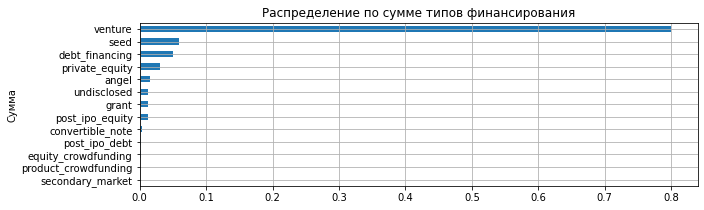

In [67]:
# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
funding_share.sort_values().plot(kind='barh',
               title=f'Распределение по сумме типов финансирования',
               ylabel='Тип финансирования',
               xlabel='Сумма',
               rot=0,
               figsize=(10, 3))
plt.grid()


# Выводим график
plt.show()

    
- Венчурное финансирование (venture) значительно преобладает над остальными типами, обеспечивая около 80% общего объёма привлечённых средств. Это свидетельствует о том, что именно венчурные инвестиции являются основным источником финансирования компаний в рассматриваемом наборе данных.
- Второе место по объёму занимает seed-финансирование (около 5.8%), за ним следуют debt_financing (5.1%) и private equity (3.0%). Остальные типы финансирования формируют менее 2% общего объёма каждый.
- Наименьший объём приходится на secondary_market (0.03%), что свидетельствует об их ограниченной роли в общем объёме финансирования компаний.

In [68]:
funding_count=(filtered_df[funding] > 0).sum().sort_values()
funding_count

secondary_market            7
post_ipo_debt              27
post_ipo_equity           164
product_crowdfunding      204
equity_crowdfunding       515
convertible_note          521
private_equity            633
undisclosed               813
grant                    1003
angel                    2937
debt_financing           3265
seed                    13375
venture                 18820
dtype: int64

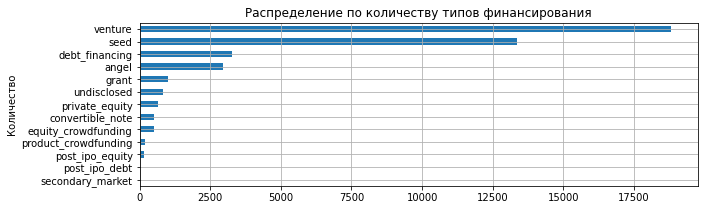

In [69]:
# Строим столбчатую диаграмму с помощью pandas 
funding_count.plot(kind='barh',
               title=f'Распределение по количеству типов финансирования',
               ylabel='Тип финансирования',
               xlabel='Количество',
               rot=0,
               figsize=(10, 3))
plt.grid()


# Выводим график
plt.show()

    
- По частоте использования также лидирует сумма венчурных инвестиций (18820).
- Наиболее редко используются secondary_market (7), post_ipo_debt (27) и post_ipo_equity (164).
- сумма инвестиций на посевной стадии поднялась по популярности на третье место (266), однако по сумме привлекла всего 1% от общего финансирования
- Сравнение двух графиков показывает, что seed используется очень часто, однако обеспечивает лишь около 5.8% общего объёма финансирования. Это говорит о том, что посевные инвестиции обычно имеют небольшой размер.

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [70]:
return_fund=['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note','debt_financing',
         'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt','secondary_market',
         'product_crowdfunding']

In [71]:
return_sum=return_df[return_fund].sum().sort_values()
return_sum

grant                       0.00
product_crowdfunding        1.86
equity_crowdfunding         3.83
secondary_market            5.20
convertible_note           34.79
post_ipo_debt              91.03
undisclosed               730.88
post_ipo_equity          1104.96
angel                    1509.23
seed                     2382.24
private_equity           3587.33
debt_financing           4734.85
venture                 40578.62
dtype: float64

In [72]:
share_return= return_sum/return_sum.sum()
share_return

grant                   0.000000
product_crowdfunding    0.000034
equity_crowdfunding     0.000070
secondary_market        0.000095
convertible_note        0.000635
post_ipo_debt           0.001662
undisclosed             0.013346
post_ipo_equity         0.020176
angel                   0.027558
seed                    0.043499
private_equity          0.065504
debt_financing          0.086458
venture                 0.740961
dtype: float64

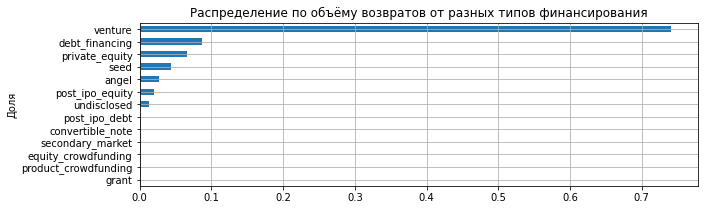

In [73]:
# Строим столбчатую диаграмму с помощью pandas
share_return.plot(kind='barh',
               title=f'Распределение по объёму возвратов от разных типов финансирования',
               ylabel='Тип финансирования',
               xlabel='Доля',
               rot=0,
               figsize=(10, 3))
plt.grid()


# Выводим график
plt.show()

    
- Наибольший объём возвратов приходится на венчурное финансирование — около 74,1% от общего объёма возвратов. Это соответствует тому, что именно данный тип финансирования привлекал наибольшие объёмы инвестиций.
- Наименьшие объёмы возвратов наблюдаются по grant (0%), product crowdfunding (0.003%) и secondary market (0.01%). Это свидетельствует о том, что данные виды финансирования либо редко приводят к возврату средств инвесторам, либо объём таких возвратов крайне невелик.
    
Распределение возвратов по типам финансирования во многом повторяет распределение объёмов привлечённых инвестиций: венчурное финансирование является лидером как по объёму вложений, так и по объёму возвращённых средств.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [74]:
filtered_df = filtered_df[filtered_df['funding_rounds'] > 0].copy()

filtered_df['avg_round_funding'] = filtered_df['funding_total_usd'] /filtered_df['funding_rounds']


In [80]:
# Динамика общего размера средств за каждый год
filtered_df['year']= filtered_df['mid_funding_at'].dt.year

In [86]:
avg_fund_year = filtered_df.groupby('year')['avg_round_funding'].median()
avg_fund_year

year
2000    2.250000e+06
2001    1.570886e+06
2002    3.225000e+06
2003    1.500000e+06
2004    3.000000e+06
2005    4.500000e+06
2006    3.900000e+06
2007    2.879167e+06
2008    2.170744e+06
2009    1.498475e+06
2010    1.250000e+06
2011    8.676850e+05
2012    6.860000e+05
2013    5.590000e+05
2014    5.606250e+05
Name: avg_round_funding, dtype: float64

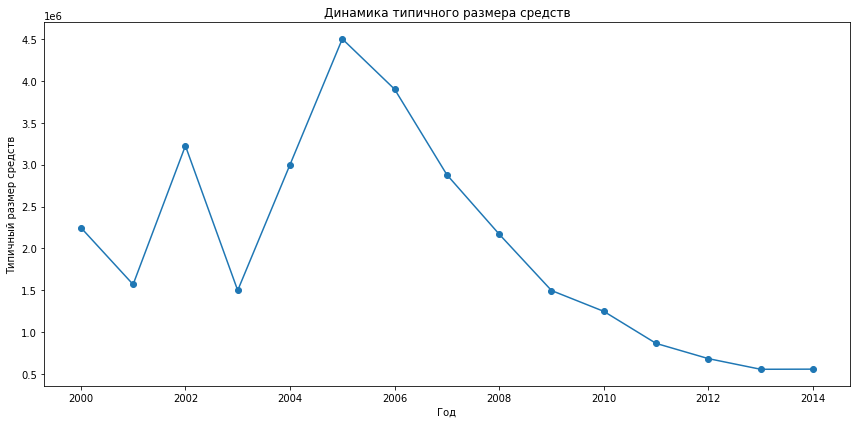

In [87]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 6))

#Создаем линейный график
avg_fund_year.plot(kind='line', marker='o')

# Настраиваем оси
plt.title('Динамика типичного размера средств')
plt.xlabel('Год')
plt.ylabel('Типичный размер средств')
plt.tight_layout()
plt.show()

In [81]:
# Динамика общего количества раундов за каждый год
rounds_year = filtered_df.groupby('year')['funding_rounds'].sum()
rounds_year

year
2000      113.0
2001       66.0
2002       98.0
2003      125.0
2004      181.0
2005      948.0
2006     1849.0
2007     2842.0
2008     3663.0
2009     4617.0
2010     6136.0
2011     7578.0
2012     9705.0
2013    12880.0
2014     7122.0
Name: funding_rounds, dtype: float64

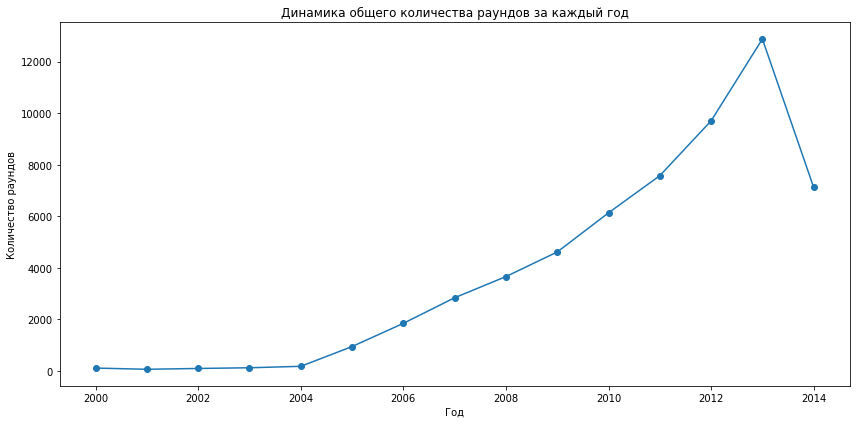

In [85]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 6))

#Создаем линейный график
rounds_year.plot(kind='line', marker='o')

# Настраиваем оси
plt.title('Динамика общего количества раундов за каждый год')
plt.xlabel('Год')
plt.ylabel('Количество раундов')
plt.tight_layout()
plt.show()

    
- Для анализа динамики использовался mid_funding_at, поскольку он отражает приблизительный момент привлечения финансирования компаниями.
    
- Максимальный типичный размер финансирования одного раунда наблюдался в 2005 году и составил около 4,5 млн долларов.

- В 2014 году после непрерывного роста инвестиционной активности произошло снижение общего количества раундов финансирования (с 12 880 до 7 122). При этом медианный объём средств, привлекаемых в рамках одного раунда, остался на уровне 2013 года (около 5.6 млн), что свидетельствует о сохранении относительно небольших размеров типичных инвестиций.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [73]:
# Исключаем средние и нишевые сегменты
massive = filtered_df[~filtered_df['market'].isin(['mid','niche'])]

In [74]:
# Создаем сводную таблицу
pivot_table=pd.pivot_table(massive, index=massive['mid_funding_at'].dt.year, columns = 'market', values = 'funding_total_usd', aggfunc='sum')
pivot_table

market,advertising,analytics,apps,automotive,big data,biotechnology,clean technology,cloud computing,consulting,curated web,...,social media,social network media,software,sports,startups,technology,travel,unknown,video,web hosting
mid_funding_at,,,,,,,,,,,,,,,,,,,,,
2000,14470000.0,14822803.0,NaN,NaN,NaN,NaN,NaN,11500000.0,4500000.0,1000000.0,...,NaN,NaN,3.173264e+07,NaN,NaN,NaN,50230.0,1839560.0,NaN,95343090.0
2001,8778321.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305000.0,...,650000.0,NaN,2.781135e+07,NaN,NaN,22160000.0,NaN,10160345.0,NaN,15000000.0
2002,24500000.0,7500000.0,NaN,NaN,NaN,NaN,3.439044e+07,NaN,NaN,4650000.0,...,NaN,NaN,1.010264e+08,200000.0,NaN,11000000.0,NaN,242132.0,NaN,NaN
2003,10500000.0,3840000.0,NaN,4530000.0,NaN,8.553118e+07,5.035294e+07,NaN,NaN,2550000.0,...,5000.0,NaN,6.608604e+07,NaN,NaN,NaN,NaN,4155202.0,5000000.0,NaN
2004,6000000.0,3000000.0,NaN,NaN,NaN,9.718486e+07,5.042795e+07,NaN,NaN,27050000.0,...,6850000.0,NaN,1.408238e+08,NaN,NaN,1750000.0,10230000.0,10847977.0,14704000.0,27000000.0
2005,127196022.0,79014044.0,NaN,22500000.0,NaN,4.800636e+08,1.942000e+07,NaN,44862000.0,53450000.0,...,14780000.0,5200000.0,9.930766e+08,1882200.0,NaN,50728425.0,27830000.0,28384331.0,6470551.0,483332632.0
2006,299299458.0,139701311.0,1310600.0,12660000.0,NaN,9.035005e+08,1.314739e+08,9951809.0,23965548.0,164673698.0,...,60169880.0,5245100.0,1.646869e+09,7000000.0,NaN,22791000.0,11700000.0,46049840.0,35171772.0,649959267.0
2007,556704331.0,98829000.0,NaN,37712601.0,7780000.0,1.704078e+09,7.497112e+08,20354343.0,70346345.0,314704515.0,...,89022516.0,24104021.0,1.686116e+09,16401580.0,NaN,180190209.0,13950000.0,35532468.0,85150644.0,361121449.0
2008,622673464.0,208077840.0,4300000.0,59478635.0,2452515.0,1.716033e+09,3.165808e+09,44375000.0,19061080.0,336500027.0,...,76034534.0,10998076.0,1.365006e+09,9554790.0,5010387.0,277726238.0,54905631.0,45345010.0,37865177.0,781623731.0


In [75]:
# Сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013
growth= pivot_table.columns[pivot_table.loc[2014] > pivot_table.loc[2013]]
growth

Index(['apps', 'big data', 'design', 'internet', 'manufacturing', 'medical',
       'real estate', 'saas', 'startups', 'technology', 'unknown'],
      dtype='object', name='market')

<Figure size 864x432 with 0 Axes>

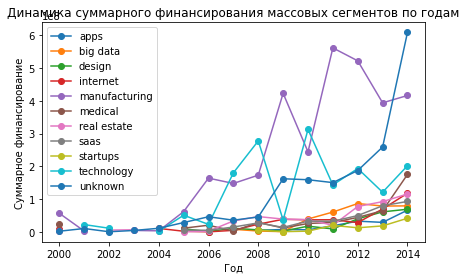

In [77]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 6))

#Создаем линейный график
pivot_table[growth].plot(kind='line', marker='o')

# Настраиваем оси
plt.title('Динамика суммарного финансирования массовых сегментов по годам')
plt.xlabel('Год')
plt.ylabel('Суммарное финансирование')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

    
- Наиболее выраженная положительная динамика наблюдается в сегментах apps, manufacturing и unknown, где значения заметно увеличиваются по сравнению с предыдущими годами.
- Начиная примерно с 2008 года, сегмент unknown демонстрирует наиболее быстрый рост, хотя в отдельные годы наблюдаются колебания.
- Сегмент manufacturing активно рос примерно с 2006 по 2010 год, после чего значения начали снижаться, что может свидетельствовать об уменьшении объёмов финансирования или снижении инвестиционной активности в данном сегменте.
- Для большинства остальных сегментов также прослеживается постепенный рост со временем, однако он менее выражен и сопровождается колебаниями.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

In [78]:
# Группируем по типу финансирования по годам
fund_sum = filtered_df.groupby(filtered_df['mid_funding_at'].dt.year)[funding].sum().reset_index().rename(columns={'mid_funding_at': 'year'})
fund_sum.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16759140.0,327962152.0,0.0,112202640.0,0.0,14000000.0,24086333.0,293114.0,0.0,3467747.0,0.0,7718867.0,0.0
1,2001,2667675.0,217519117.0,0.0,36596784.0,1500000.0,5829217.0,1000000.0,100000.0,0.0,0.0,0.0,0.0,0.0
2,2002,10465192.0,306940622.0,0.0,42323731.0,0.0,15309671.0,3000000.0,0.0,7500000.0,300000.0,0.0,0.0,0.0
3,2003,15318355.0,372234425.0,0.0,10280000.0,0.0,1050000.0,5629661.0,16850717.0,0.0,0.0,0.0,0.0,0.0
4,2004,18104728.0,664150451.0,0.0,62912359.0,0.0,30816623.0,11013741.0,10363600.0,0.0,0.0,0.0,0.0,0.0


In [79]:
# Соединяем данные в единый датафрейм df
df = fund_sum.merge(return_df, on='year', suffixes=('_funding', '_return'))
df.head()

,year,seed_funding,venture_funding,equity_crowdfunding_funding,undisclosed_funding,convertible_note_funding,debt_financing_funding,angel_funding,grant_funding,private_equity_funding,...,undisclosed_return,convertible_note_return,debt_financing_return,angel_return,grant_return,private_equity_return,post_ipo_equity_return,post_ipo_debt_return,secondary_market_return,product_crowdfunding_return
0,2000,16759140.0,327962152.0,0.0,112202640.0,0.0,14000000.0,24086333.0,293114.0,0.0,...,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2667675.0,217519117.0,0.0,36596784.0,1500000.0,5829217.0,1000000.0,100000.0,0.0,...,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,10465192.0,306940622.0,0.0,42323731.0,0.0,15309671.0,3000000.0,0.0,7500000.0,...,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,15318355.0,372234425.0,0.0,10280000.0,0.0,1050000.0,5629661.0,16850717.0,0.0,...,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,18104728.0,664150451.0,0.0,62912359.0,0.0,30816623.0,11013741.0,10363600.0,0.0,...,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [80]:
#Находим долю
for col in funding:
    df[col + '_ratio'] = (
        df[col + '_return'] /
        (df[col + '_funding'] + 1e-60)
    )

In [81]:
# Формируем корректный список столбцов
cols_to_process = [c + suffix for c in funding for suffix in ['_ratio']]
# Заменяем аномалии пропусками методом IQR
for col in cols_to_process:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df.loc[(df[col] < lower) | (df[col] > upper), col] = np.nan

In [82]:
df.head()

,year,seed_funding,venture_funding,equity_crowdfunding_funding,undisclosed_funding,convertible_note_funding,debt_financing_funding,angel_funding,grant_funding,private_equity_funding,...,undisclosed_ratio,convertible_note_ratio,debt_financing_ratio,angel_ratio,grant_ratio,private_equity_ratio,post_ipo_equity_ratio,post_ipo_debt_ratio,secondary_market_ratio,product_crowdfunding_ratio
0,2000,16759140.0,327962152.0,0.0,112202640.0,0.0,14000000.0,24086333.0,293114.0,0.0,...,6.970424e-07,0.000000e+00,6.185714e-07,2.669564e-07,0.0,0.000000e+00,2.710694e-07,0.0,2.591054e-08,0.0
1,2001,2667675.0,217519117.0,0.0,36596784.0,1500000.0,5829217.0,1000000.0,100000.0,0.0,...,5.874833e-07,6.666667e-09,7.702578e-07,1.180000e-06,0.0,0.000000e+00,4.600000e+59,0.0,4.600000e+59,0.0
2,2002,10465192.0,306940622.0,0.0,42323731.0,0.0,15309671.0,3000000.0,0.0,7500000.0,...,6.088783e-07,NaN,2.233882e-07,1.136667e-06,0.0,2.013333e-07,1.133333e-06,0.0,6.000000e+58,0.0
3,2003,15318355.0,372234425.0,0.0,10280000.0,0.0,1050000.0,5629661.0,16850717.0,0.0,...,9.143969e-07,1.000000e+58,1.038095e-06,6.057203e-07,0.0,NaN,NaN,0.0,8.000000e+58,0.0
4,2004,18104728.0,664150451.0,0.0,62912359.0,0.0,30816623.0,11013741.0,10363600.0,0.0,...,5.275593e-07,1.000000e+58,4.396978e-07,8.335043e-07,0.0,NaN,NaN,0.0,5.500000e+59,0.0


Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

<Figure size 864x432 with 0 Axes>

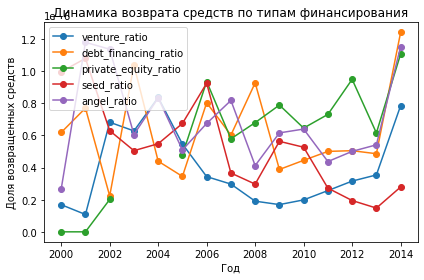

In [85]:
plot_df = df.set_index('year')[['venture_ratio','debt_financing_ratio','private_equity_ratio','seed_ratio','angel_ratio']]

# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 6))

plot_df.plot(kind='line', marker='o')

# Настраиваем оси
plt.title('Динамика возврата средств по типам финансирования')
plt.xlabel('Год')
plt.ylabel('Доля возвращенных средств')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

    
- Наиболее устойчивую положительную динамику демонстрирует venture, несмотря на временные колебания, после 2011 года нормированный показатель возврата постепенно увеличивается и достигает максимального значения к концу 2014.
- Для private equity также наблюдается общая тенденция к росту, хотя изменения происходят менее равномерно и сопровождаются заметными колебаниями.
- Seed-финансирование, напротив, демонстрирует скорее снижение нормированного показателя возврата в последние годы исследования.
    
В целом наиболее устойчивый рост нормированного показателя возврата средств наблюдается у venture и, в меньшей степени, у private equity. Для остальных типов финансирования характерны значительные колебания между годами, что не позволяет говорить о стабильной восходящей тенденции.

## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.

## Подведём итоги

В ходе исследования были проанализированы данные о финансировании стартапов и возврате инвестиций. Основной датасет содержал информацию о 54294 компаний, их сегментах рынка, объёмах финансирования, количестве раундов и датах привлечения инвестиций. Дополнительно были использованы данные о ежегодных объёмах возвратов средств по различным типам финансирования.

В процессе исследования были выполнены следующие этапы:

- проведена предобработка данных: исправлены названия столбцов и типы данных, обработаны пропуски, удалены дубликаты и записи без информации о суммарном финансировании
- компании были разделены по длительности финансирования и по размеру рыночных сегментов
- проведён анализ распределения объёмов финансирования и выявлены компании с аномально высоким объёмом инвестиций методом IQR;
- исследованы объёмы и популярность различных типов финансирования
- рассчитан средний объём одного раунда финансирования и изучена динамика инвестиционной активности по годам
- рассчитаны нормированные показатели возврата средств и проведено сравнение эффективности различных типов финансирования 

### Основные результаты исследования

- Исследовательский анализ позволил выявить несколько закономерностей.

- Большинство компаний (58.9%) получили финансирование только один раз. При этом около 30% компаний привлекали инвестиции более одного года, а лишь 11% были профинансированы в течение периода менее одного года.

- Компании со сроком финансирования более года привлекли наибольший объём инвестиций (61% общего объёма финансирования). Это свидетельствует о том, что долгосрочное финансирование характерно для наиболее больших объёмов инвестиций.

- Анализ рыночных сегментов показал, что большинство компаний относится к массовым сегментам, однако по количеству различных направлений преобладают именно нишевые сегменты. Таким образом, рынок характеризуется небольшим числом крупных направлений и большим разнообразием специализированных отраслей.

- Во всех категориях сегментов большинство компаний привлекает относительно небольшие суммы, тогда как небольшое количество компаний получает существенно более крупные инвестиции.

- После исключения аномальных наблюдений было установлено, что данные за 2014 год можно считать полными, а наиболее активный период финансирования начинается примерно с 2000 года, когда количество инвестиционных раундов стабильно превышает 50 в год.

### Особенности финансирования и возврата инвестиций

- Анализ различных типов финансирования показал, что лидирующее положение занимает венчурное финансирование.
На его долю приходится около 80% общего объёма привлечённых средств и 18820 случаев использования, что делает его одновременно самым популярным и основным источником инвестиций.

- Второе место по популярности занимает seed-финансирование, однако его вклад в общий объём инвестиций значительно меньше, около 6%, что соответствует особенностям финансирования компаний на ранних стадиях развития.

- Такие виды финансирования, как secondary market, post IPO debt и product crowdfunding, используются крайне редко и обеспечивают незначительные объёмы инвестиций.

Анализ возврата средств показал аналогичную картину.
- На долю венчурного финансирования приходится около 74% всех возвратов инвесторам. Существенные объёмы возвратов также наблюдаются у debt financing и private equity, тогда как остальные типы финансирования обеспечивают значительно меньшие суммы возврата.

- После нормирования показателей возврата было установлено, что наиболее устойчивую положительную динамику демонстрирует венчурное финансирование. В меньшей степени аналогичная тенденция наблюдается для private equity. Для остальных типов финансирования характерны значительные колебания между годами.

### Рекомендации

На основании проведённого анализа наиболее перспективным направлением для инвестиций можно считать массовые сегменты рынка, поскольку именно в них сосредоточено большинство компаний и основной объём привлечённого капитала. Среди отдельных отраслей наиболее устойчивую положительную динамику в последние годы демонстрировали такие направления, как apps, technology и manufacturing, что делает их потенциально привлекательными для дальнейших вложений.

В качестве основного инструмента финансирования рекомендуется использовать венчурное финансирование. Оно не только является самым распространённым типом инвестиций, но и обеспечивает наибольший объём привлечённых средств и возвратов инвесторам. Кроме того, нормированный показатель возврата по данному типу финансирования демонстрирует наиболее устойчивую положительную динамику в течение рассматриваемого периода.